In [1]:
# Visualize and Compare Activation Functions
# o Train the same MLP using Sigmoid, Tanh, and ReLU.
# o Plot training speed, accuracy, and gradient flow.
# o Discuss vanishing/exploding gradient issues

In [2]:
# Load libraries
import tensorflow as tf
import pandas as pd
import matplotlib.pyplot as plt
import time
import numpy as np

I0000 00:00:1794467589.216976    8275 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794467589.322912    8275 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794467595.879590    8275 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [3]:
# load and preprocess data
train = pd.read_csv("dataset/Handwritten/mnist_train.csv")
test = pd.read_csv("dataset/Handwritten/mnist_test.csv")

x_train = train.iloc[:, 1:].values.astype('float32') / 255.0
y_train = train.iloc[:, 0].values

x_test = test.iloc[:, 1:].values.astype('float32') / 255.0
y_test = test.iloc[:, 0].values

print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)
print("Missing values:", train.isnull().sum().sum())

Training data: (60000, 784)
Testing data: (10000, 784)
Missing values: 0


In [4]:
# Build and train three MLP Model
histories = []
results = []
times = []
models = []

for activation in ['sigmoid', 'tanh', 'relu']:
    tf.keras.utils.set_random_seed(42)

    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(784,)),
        tf.keras.layers.Dense(128, activation=activation),
        tf.keras.layers.Dense(64, activation=activation),
        tf.keras.layers.Dense(10, activation='softmax')
    ])

    model.compile(optimizer='adam',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])

    start = time.time()
    history = model.fit(x_train, y_train, epochs=5,
                        batch_size=64, validation_split=0.1, verbose=1)
    times.append(time.time() - start)

    loss, accuracy = model.evaluate(x_test, y_test, verbose=0)

    histories.append(history)
    results.append(accuracy)
    models.append(model)

    print(activation, "Accuracy:", round(accuracy * 100, 2), "%")
    print("Training time:", round(times[-1], 2), "seconds")

E0000 00:00:1794467627.306700    8275 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
W0000 00:00:1794467628.833605    8275 cpu_allocator_impl.cc:82] Allocation of 169344000 exceeds 10% of free system memory.


Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 18s 18ms/step - accuracy: 0.8492 - loss: 0.6215 - val_accuracy: 0.9368 - val_loss: 0.2241
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 14s 16ms/step - accuracy: 0.9334 - loss: 0.2291 - val_accuracy: 0.9585 - val_loss: 0.1558
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 15s 17ms/step - accuracy: 0.9505 - loss: 0.1690 - val_accuracy: 0.9650 - val_loss: 0.1244
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 15s 18ms/step - accuracy: 0.9617 - loss: 0.1318 - val_accuracy: 0.9695 - val_loss: 0.1054
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 14s 17ms/step - accuracy: 0.9697 - loss: 0.1054 - val_accuracy: 0.9708 - val_loss: 0.0931


W0000 00:00:1794467712.192017    8275 cpu_allocator_impl.cc:82] Allocation of 31360000 exceeds 10% of free system memory.


sigmoid Accuracy: 96.52 %
Training time: 84.15 seconds
Epoch 1/5


W0000 00:00:1794467715.483736    8275 cpu_allocator_impl.cc:82] Allocation of 169344000 exceeds 10% of free system memory.


844/844 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.9116 - loss: 0.3126

W0000 00:00:1794467730.892502    8275 cpu_allocator_impl.cc:82] Allocation of 18816000 exceeds 10% of free system memory.


844/844 ━━━━━━━━━━━━━━━━━━━━ 16s 17ms/step - accuracy: 0.9116 - loss: 0.3126 - val_accuracy: 0.9570 - val_loss: 0.1487
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 15s 17ms/step - accuracy: 0.9564 - loss: 0.1500 - val_accuracy: 0.9682 - val_loss: 0.1056
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 14s 17ms/step - accuracy: 0.9708 - loss: 0.1022 - val_accuracy: 0.9725 - val_loss: 0.0924
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 14s 17ms/step - accuracy: 0.9790 - loss: 0.0736 - val_accuracy: 0.9730 - val_loss: 0.0883
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 15s 18ms/step - accuracy: 0.9850 - loss: 0.0549 - val_accuracy: 0.9730 - val_loss: 0.0868


W0000 00:00:1794467790.393835    8275 cpu_allocator_impl.cc:82] Allocation of 31360000 exceeds 10% of free system memory.


tanh Accuracy: 97.16 %
Training time: 75.25 seconds
Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 17s 19ms/step - accuracy: 0.9154 - loss: 0.2931 - val_accuracy: 0.9608 - val_loss: 0.1296
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 14s 16ms/step - accuracy: 0.9615 - loss: 0.1271 - val_accuracy: 0.9688 - val_loss: 0.0979
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 14s 16ms/step - accuracy: 0.9747 - loss: 0.0862 - val_accuracy: 0.9733 - val_loss: 0.0879
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 14s 17ms/step - accuracy: 0.9808 - loss: 0.0634 - val_accuracy: 0.9735 - val_loss: 0.0896
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 14s 17ms/step - accuracy: 0.9859 - loss: 0.0475 - val_accuracy: 0.9730 - val_loss: 0.0959
relu Accuracy: 97.23 %
Training time: 74.06 seconds


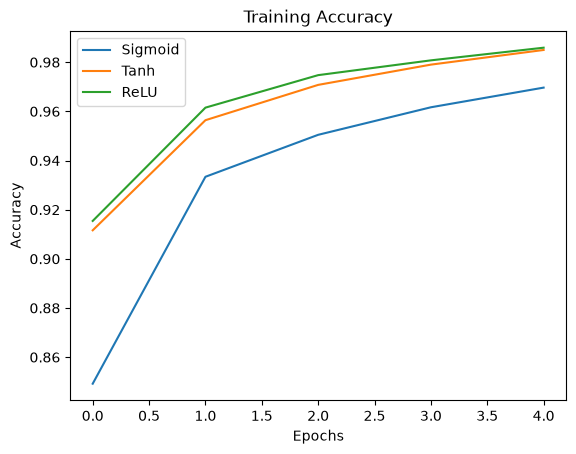

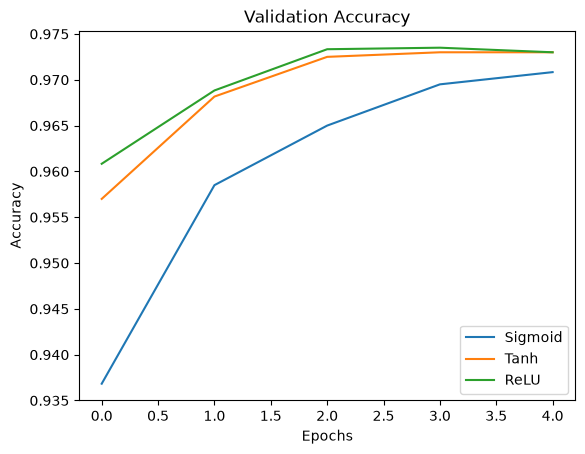

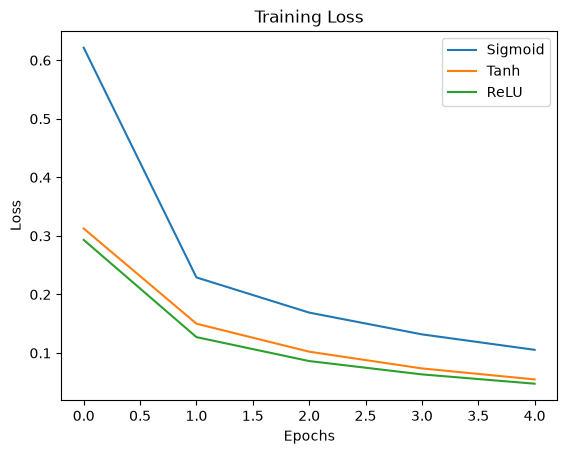

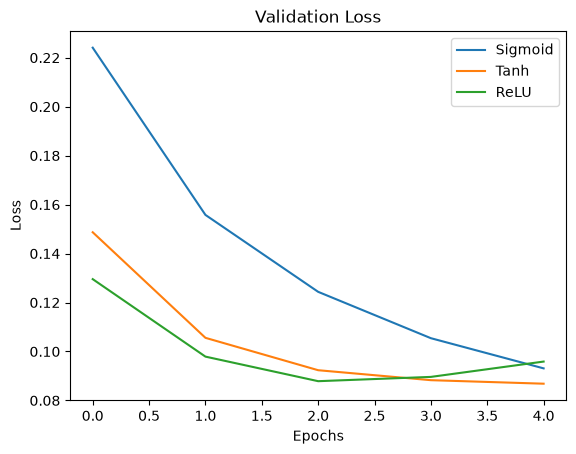

In [5]:
# Plot training and validation accuracy
names = ['Sigmoid', 'Tanh', 'ReLU']

for i, h in enumerate(histories):
    plt.plot(h.history['accuracy'], label=names[i])

plt.title("Training Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

for i, h in enumerate(histories):
    plt.plot(h.history['val_accuracy'], label=names[i])

plt.title("Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

# Plot training and validation loss
for i, h in enumerate(histories):
    plt.plot(h.history['loss'], label=names[i])

plt.title("Training Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

for i, h in enumerate(histories):
    plt.plot(h.history['val_loss'], label=names[i])

plt.title("Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

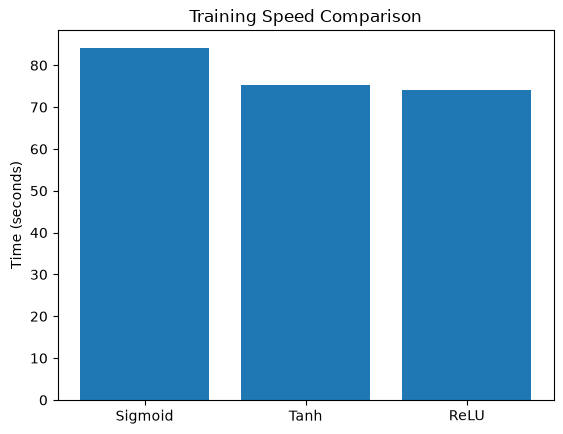

Sigmoid Test Accuracy: 96.52 %
Tanh Test Accuracy: 97.16 %
ReLU Test Accuracy: 97.23 %
Fastest model: ReLU
Most accurate model: ReLU


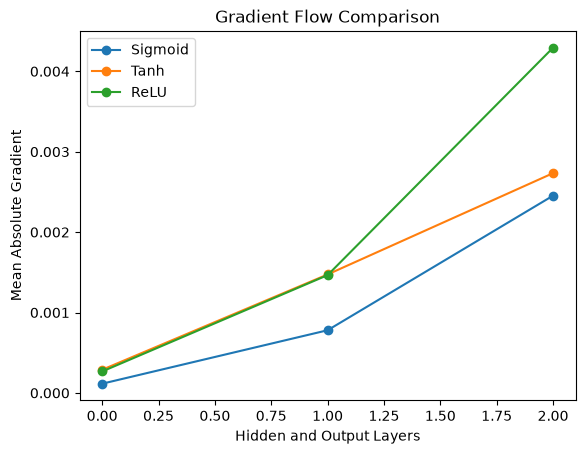

In [6]:
# Compare training speed and test accuracy
plt.bar(names, times)
plt.title("Training Speed Comparison")
plt.ylabel("Time (seconds)")
plt.show()

for name, acc in zip(names, results):
    print(name, "Test Accuracy:", round(acc * 100, 2), "%")

print("Fastest model:", names[np.argmin(times)])
print("Most accurate model:", names[np.argmax(results)])

# Visualize gradient flow
for i, model in enumerate(models):
    with tf.GradientTape() as tape:
        output = model(x_train[:64])
        loss = tf.reduce_mean(
            tf.keras.losses.sparse_categorical_crossentropy(y_train[:64], output)
        )

    gradients = tape.gradient(loss, model.trainable_variables)
    values = [tf.reduce_mean(tf.abs(g)).numpy()
              for g, v in zip(gradients, model.trainable_variables)
              if len(v.shape) == 2]

    plt.plot(values, marker='o', label=names[i])

plt.title("Gradient Flow Comparison")
plt.xlabel("Hidden and Output Layers")
plt.ylabel("Mean Absolute Gradient")
plt.legend()
plt.show()